# Google Play Store Analysis
**Author:** [Your Full Name]
**Track:** Data Analytics — OIBSIP
**Task:** Level 2, Task 4 — Google Play Store Analysis

**Objective:** Clean and analyze the Google Play Store apps dataset to understand app
category trends, ratings, installs, and pricing, and combine it with user review sentiment
to find patterns in what makes an app succeed.

**Datasets:** Google Play Store Apps (Kaggle) — `googleplaystore.csv` (10,841 apps) and
`googleplaystore_user_reviews.csv` (64,295 user reviews with pre-labeled sentiment).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
%matplotlib inline

apps = pd.read_csv("googleplaystore.csv")
reviews = pd.read_csv("googleplaystore_user_reviews.csv")

apps.head()


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## 1. Initial Inspection

In [2]:
print("Apps dataset shape:", apps.shape)
print("Reviews dataset shape:", reviews.shape)
print()
print("Apps dtypes:")
print(apps.dtypes)
print()
print("Apps missing values:")
print(apps.isnull().sum())
print()
print("Apps duplicate rows:", apps.duplicated().sum())
print()
print("Reviews missing values:")
print(reviews.isnull().sum())


Apps dataset shape: (10841, 13)
Reviews dataset shape: (64295, 5)

Apps dtypes:
App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object

Apps missing values:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Apps duplicate rows: 483

Reviews missing values:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


**Observation:** *(Write here after running — note the duplicate app rows, the missing
Rating values, and that most of the reviews file's nulls come from apps with no review
text collected.)*

## 2. Cleaning the Apps Dataset

Several columns are stored as text with symbols that need to be removed before they can be
used numerically: `Installs` has commas and a trailing `+`, `Price` has a `$` sign, and
`Size` mixes `"19M"`-style text with `"Varies with device"`.

In [3]:
# Drop exact duplicate rows
before = len(apps)
apps = apps.drop_duplicates()
print(f"Dropped {before - len(apps)} duplicate rows")

# Drop duplicate App names, keeping the entry with the most reviews (most up to date)
apps['Reviews'] = pd.to_numeric(apps['Reviews'], errors='coerce')
apps = apps.sort_values('Reviews', ascending=False).drop_duplicates(subset='App', keep='first')
print(f"Rows after removing duplicate app names: {len(apps)}")


Dropped 483 duplicate rows
Rows after removing duplicate app names: 9660


In [4]:
# Clean Installs: remove commas and '+', convert to numeric
apps['Installs'] = apps['Installs'].astype(str).str.replace(',', '', regex=False)
apps['Installs'] = apps['Installs'].str.replace('+', '', regex=False)
apps = apps[apps['Installs'] != 'Free']  # drop the one corrupted row seen in raw data
apps['Installs'] = pd.to_numeric(apps['Installs'], errors='coerce')

# Clean Price: remove '$', convert to numeric
apps['Price'] = apps['Price'].astype(str).str.replace('$', '', regex=False)
apps['Price'] = pd.to_numeric(apps['Price'], errors='coerce')

# Clean Size: convert 'M' (megabytes) and 'k' (kilobytes) to numeric MB; mark 'Varies with device' as missing
def clean_size(x):
    x = str(x)
    if 'M' in x:
        return float(x.replace('M', ''))
    elif 'k' in x:
        return float(x.replace('k', '')) / 1024
    else:
        return np.nan

apps['Size_MB'] = apps['Size'].apply(clean_size)

print("Installs sample:", apps['Installs'].dropna().unique()[:5])
print("Price sample:", apps['Price'].dropna().unique()[:5])
print("Size_MB sample:", apps['Size_MB'].dropna().unique()[:5])


Installs sample: [1000000000  100000000  500000000   50000000   10000000]
Price sample: [0.   6.99 0.99 2.99 1.99]
Size_MB sample: [98. 76. 97. 74. 40.]


**Justification:** `Installs` and `Price` needed their text symbols stripped before
they could be treated as numbers. `Size` could not simply be converted — a large share of
rows say `"Varies with device"` (the developer lets Android pick automatically), so those
are kept as missing (NaN) rather than guessed, since there's no reliable way to know the
actual size for those apps.

In [5]:
# Fix Rating: fill missing with the median rating (ratings are usually clustered narrowly around 4.0-4.5)
apps['Rating'] = apps['Rating'].fillna(apps['Rating'].median())

# Drop the single row with a corrupted Type ('0' instead of Free/Paid)
apps = apps[apps['Type'].isin(['Free', 'Paid'])]

# Fill remaining small categorical gaps with the most frequent value
apps['Content Rating'] = apps['Content Rating'].fillna(apps['Content Rating'].mode()[0])
apps['Current Ver'] = apps['Current Ver'].fillna('Unknown')
apps['Android Ver'] = apps['Android Ver'].fillna('Unknown')

print("Remaining nulls in key columns:")
print(apps[['Rating', 'Type', 'Content Rating']].isnull().sum())


Remaining nulls in key columns:
Rating            0
Type              0
Content Rating    0
dtype: int64


**Justification:** Missing `Rating` values were filled with the median rather than
dropped, since ratings cluster tightly (mostly 4.0-4.5) and dropping ~1,400 rows would lose
a meaningful share of the dataset. `Content Rating`, `Current Ver`, and `Android Ver` gaps
are small and filled with the mode or an explicit "Unknown" label rather than guessed
values.

## 3. Category Analysis — Which Categories Are Most Saturated

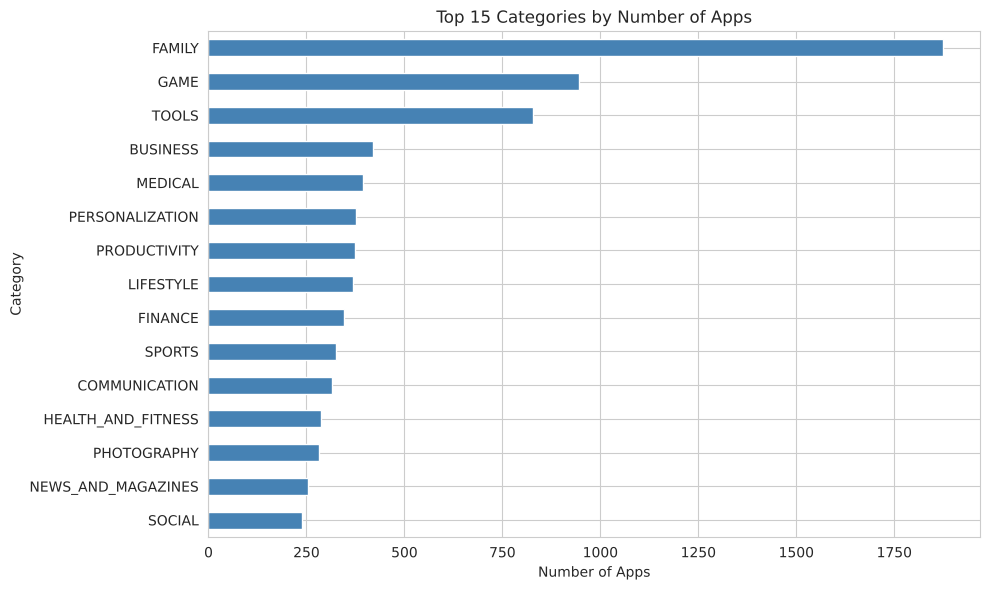

In [6]:
category_counts = apps['Category'].value_counts().head(15)

plt.figure(figsize=(10,6))
category_counts.plot(kind='barh', color='steelblue')
plt.title('Top 15 Categories by Number of Apps')
plt.xlabel('Number of Apps')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


**Observation:** *(e.g. "Family and Game categories have by far the most apps,
meaning they are the most crowded/competitive spaces for a new app to launch into.")*

## 4. Ratings Analysis

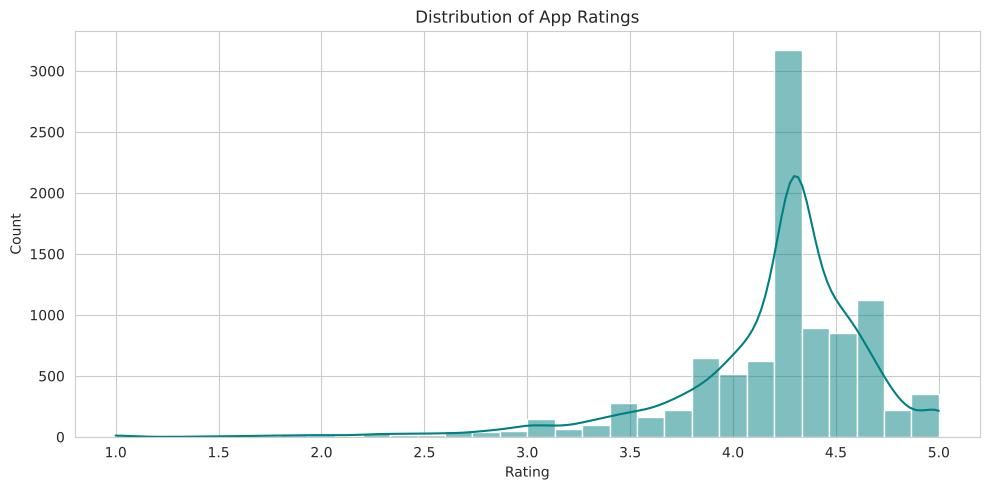

In [7]:
plt.figure(figsize=(10,5))
sns.histplot(apps['Rating'], bins=30, kde=True, color='teal')
plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.tight_layout()
plt.show()


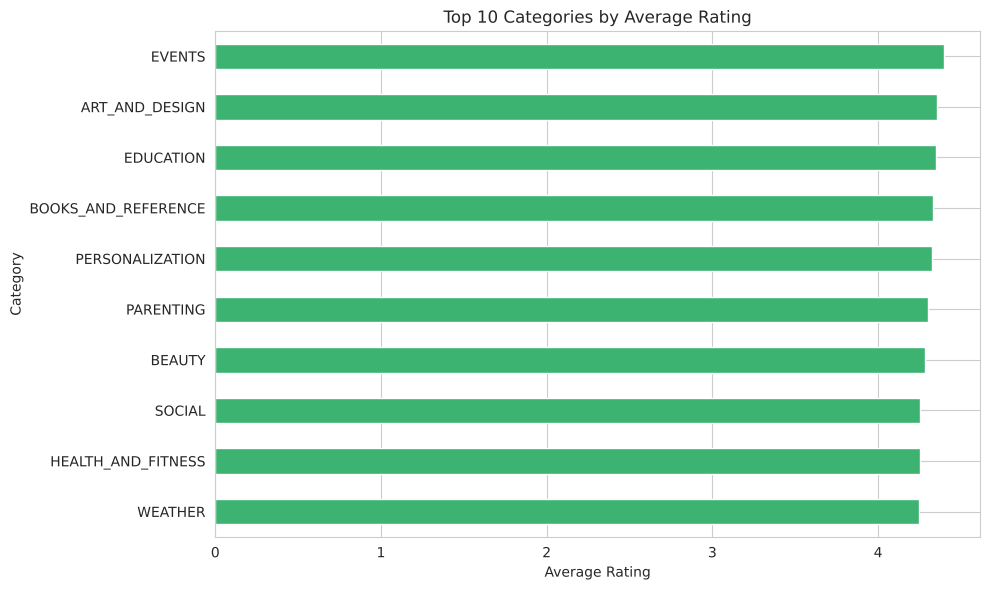

In [8]:
avg_rating_by_category = apps.groupby('Category')['Rating'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))
avg_rating_by_category.plot(kind='barh', color='mediumseagreen')
plt.title('Top 10 Categories by Average Rating')
plt.xlabel('Average Rating')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


**Observation:** *(e.g. "Most ratings cluster between 4.0 and 4.5 — very few apps are
rated poorly, likely because low-rated apps get removed or abandoned by users before
leaving a rating. Some niche categories top the average rating chart despite having far
fewer apps than Family or Game.")*

## 5. Size vs Installs

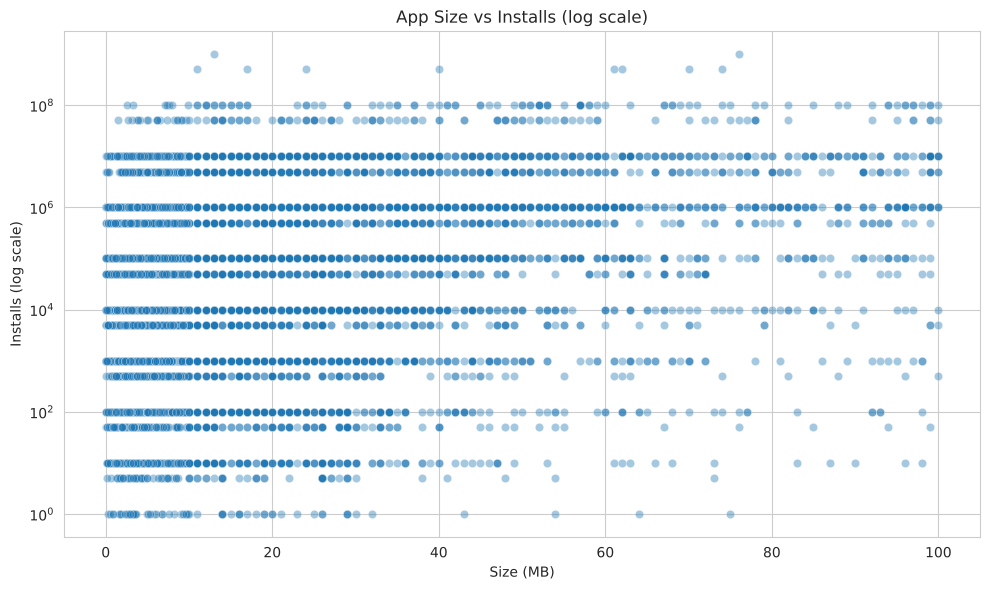

In [9]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=apps, x='Size_MB', y='Installs', alpha=0.4)
plt.yscale('log')
plt.title('App Size vs Installs (log scale)')
plt.xlabel('Size (MB)')
plt.ylabel('Installs (log scale)')
plt.tight_layout()
plt.show()


**Observation:** *(e.g. "There's no strong relationship between app size and install
count — both small and large apps can reach very high install numbers, suggesting size
isn't a major factor in an app's popularity.")*

## 6. Pricing Analysis — Free vs Paid

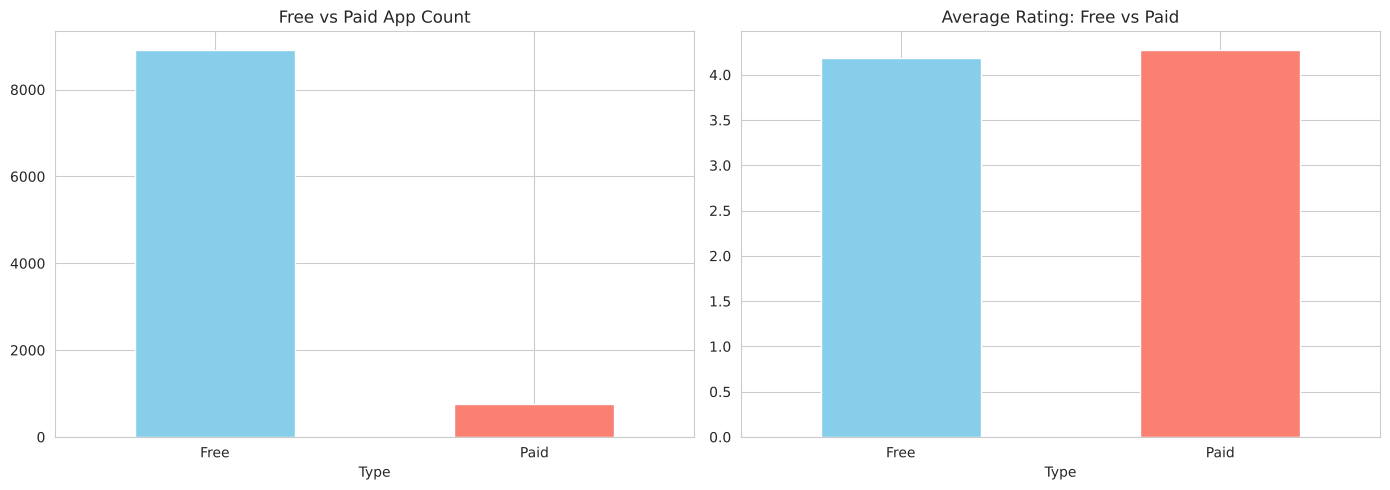

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

apps['Type'].value_counts().plot(kind='bar', ax=axes[0], color=['skyblue','salmon'])
axes[0].set_title('Free vs Paid App Count')
axes[0].tick_params(axis='x', rotation=0)

apps.groupby('Type')['Rating'].mean().plot(kind='bar', ax=axes[1], color=['skyblue','salmon'])
axes[1].set_title('Average Rating: Free vs Paid')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


**Observation:** *(e.g. "The vast majority of apps on the Play Store are free — paid
apps are a small minority. Average ratings are very similar between free and paid apps,
suggesting price alone doesn't determine user satisfaction.")*

## 7. Sentiment Analysis on User Reviews

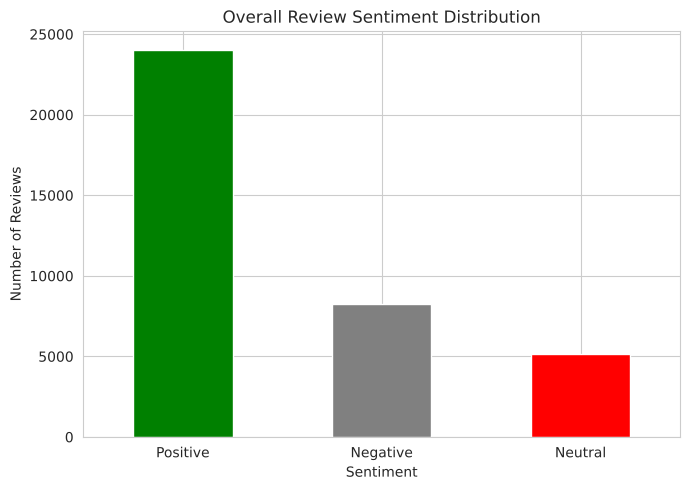

Sentiment
Positive    23998
Negative     8271
Neutral      5163
Name: count, dtype: int64

Positive rate: 64.1%


In [11]:
# Merge sentiment data with app info
reviews_clean = reviews.dropna(subset=['Sentiment'])

sentiment_counts = reviews_clean['Sentiment'].value_counts()

plt.figure(figsize=(7,5))
sentiment_counts.plot(kind='bar', color=['green','gray','red'])
plt.title('Overall Review Sentiment Distribution')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(sentiment_counts)
print()
print(f"Positive rate: {sentiment_counts.get('Positive', 0) / len(reviews_clean) * 100:.1f}%")


**Observation:** *(e.g. "The large majority of reviews are positive, which aligns
with the earlier finding that most app ratings are high — users who leave a review tend to
be satisfied overall.")*

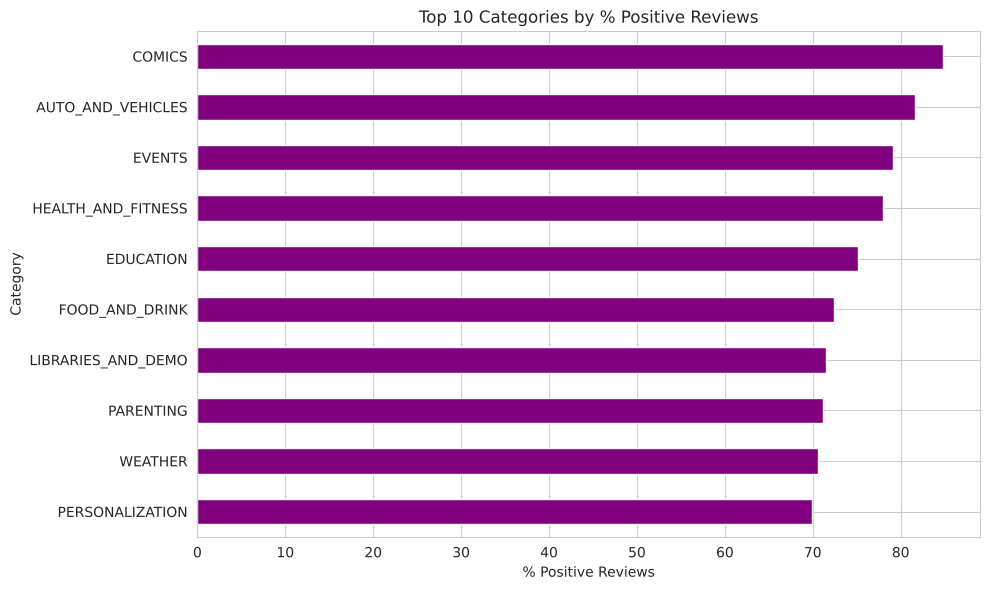

In [12]:
# Merge sentiment summary into app-level data to compare sentiment across categories
app_sentiment = reviews_clean.merge(apps[['App', 'Category']], on='App', how='inner')

sentiment_by_category = (
    app_sentiment.groupby('Category')['Sentiment']
    .apply(lambda x: (x == 'Positive').mean() * 100)
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))
sentiment_by_category.plot(kind='barh', color='purple')
plt.title('Top 10 Categories by % Positive Reviews')
plt.xlabel('% Positive Reviews')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


**Observation:** *(e.g. "Certain categories have a notably higher share of positive
reviews than others, which could point to which app categories best satisfy user
expectations — useful context for anyone deciding what type of app to build.")*

## 8. Conclusion — Key Insights

*(Fill in after reviewing your real output above.)*

1. **Insight 1:** ...
2. **Insight 2:** ...
3. **Insight 3:** ...
